<a href="https://colab.research.google.com/github/rashidsohaib10232/Front-end-battle/blob/main/Function_Transformer_%7C_Log_Transform_%7C_Reciprocal_Transform_%7C_Square_Root_Transform.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [19]:
df = pd.read_csv('train.csv', usecols=['Age','Fare','Survived'])


In [20]:
df['Age'].fillna(df['Age'].mean(), inplace=True)

/tmp/ipykernel_4585/1698716155.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


In [21]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [22]:
X=df.iloc[:,1:3]
y=df.iloc[:,0]
print(X.head())
print(y.head())

    Age     Fare
0  22.0   7.2500
1  38.0  71.2833
2  26.0   7.9250
3  35.0  53.1000
4  35.0   8.0500
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [23]:
df.isnull().sum()

,0
Survived,0
Age,0
Fare,0


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=0)

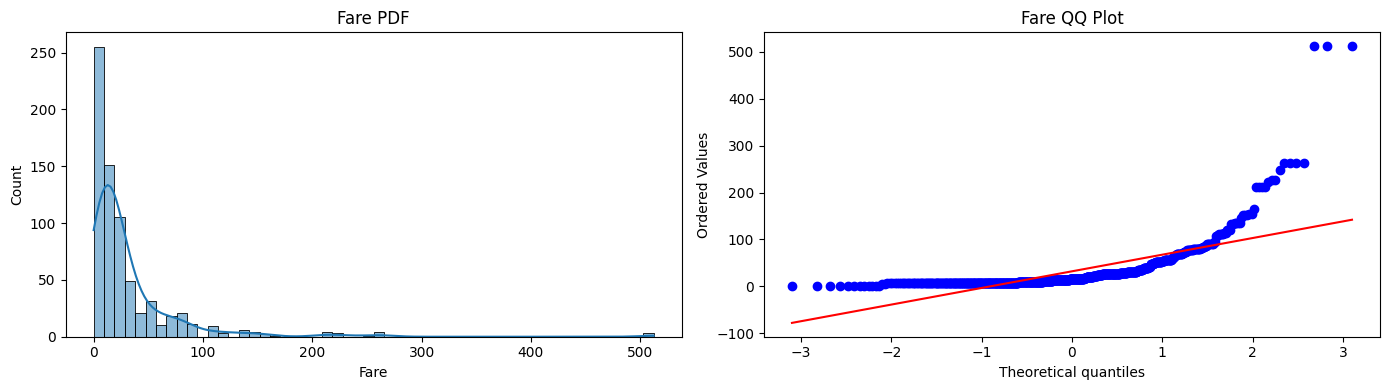

In [25]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train['Fare'], kde=True)
plt.title("Fare PDF")

plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title("Fare QQ Plot")

plt.tight_layout()
plt.show()

In [26]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [27]:
X_train.isnull().sum()

,0
Age,0
Fare,0


In [28]:
clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

print("Accuracy LR",accuracy_score(y_test, y_pred))
print("Accuracy DT",accuracy_score(y_test, y_pred2))

Accuracy LR 0.6983240223463687
Accuracy DT 0.6703910614525139


In [29]:
trf = FunctionTransformer(func=np.log1p)

In [30]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)


In [31]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [32]:
clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

print("Accuracy LR",accuracy_score(y_test, y_pred))
print("Accuracy DT",accuracy_score(y_test, y_pred2))

Accuracy LR 0.6145251396648045
Accuracy DT 0.6145251396648045


In [33]:
clf_log = LogisticRegression()
clf2_log = DecisionTreeClassifier()

# Train ONLY on transformed data
clf_log.fit(X_train_transformed, y_train)
clf2_log.fit(X_train_transformed, y_train)

# Predict using transformed data
y_pred_log = clf_log.predict(X_test_transformed)
y_pred2_log = clf2_log.predict(X_test_transformed)

print("Corrected Accuracy LR (Log Transformed):", accuracy_score(y_test, y_pred_log))
print("Corrected Accuracy DT (Log Transformed):", accuracy_score(y_test, y_pred2_log))

Corrected Accuracy LR (Log Transformed): 0.7039106145251397
Corrected Accuracy DT (Log Transformed): 0.6703910614525139


# cross validate


In [34]:
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf, X_test_transformed, y_test, cv=10, scoring='accuracy')))
print("DT",np.mean(cross_val_score(clf2, X_test_transformed, y_test, cv=10, scoring='accuracy')))

LR 0.7212418300653595
DT 0.6872549019607843


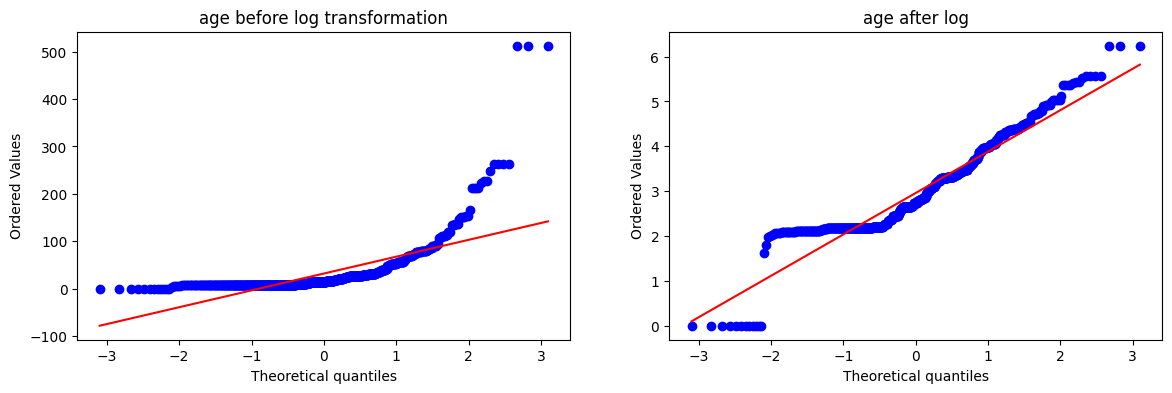

In [35]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('fare before log transformation')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist='norm', plot = plt)
plt.title('fare after log')

plt.show()


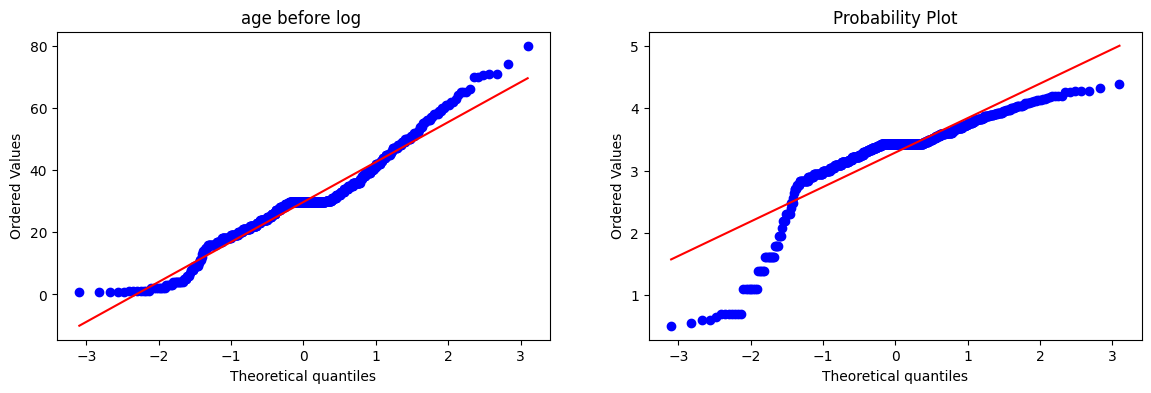

In [36]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('age before log ')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist ='norm', plot = plt)

plt.show()